# Lab01 - sprint 1

## Independence: n_center и n_edge

### Description

Проверяем, независимы ли n_center (число дефектных чипов в центре, $r<0.5$) и n_edge (у края, $r>0.8$). Обе величины считаются на одной и той же пластине, поэтому зависимость вполне возможна: общий уровень загрязнения, состояние камеры, партия реагентов влияют на обе зоны сразу. Но заранее это не утверждаем, а проверяем несколькими способами.

**Гипотезы.**
$H_0$: $P(n_c=i,\ n_e=j)=P(n_c=i)\,P(n_e=j)$ для всех $i,j$ — величины независимы.
$H_1$: величины зависимы.
Уровень значимости $\alpha=0.05$.

**Чего ожидать по теории.** Три простые модели дают разный ответ.
1. *Пуассон с фиксированной интенсивностью.* Пусть общее число дефектов $N\sim\text{Poisson}(\lambda)$, и каждый дефект независимо попадает в центр с вероятностью $p_c$, а на край с вероятностью $p_e$. Тогда (через производящую функцию)
$$\mathbb E\,s^{n_c}t^{n_e}=e^{\lambda(p_cs+p_et+1-p_c-p_e-1)}=e^{\lambda p_c(s-1)}\cdot e^{\lambda p_e(t-1)},$$
то есть функция распадается на произведение, и $n_c$, $n_e$ **независимы** (это свойство «прореживания» Пуассона).
2. *Интенсивность случайна* (у каждой пластины свой уровень брака $\Lambda$, например гамма — тогда маргинально ОБР). Условно на $\Lambda$ величины независимы, но $\operatorname{Cov}(n_c,n_e)=p_cp_e\operatorname{Var}\Lambda>0$. Получается **положительная** связь через общую причину.
3. *Общее число дефектов $N$ фиксировано.* Тогда схема мультиномиальная: $\operatorname{Cov}(n_c,n_e)=-Np_cp_e<0$. Если в центре больше, на остальное остаётся меньше, и связь **отрицательная**.

В ноутбуке про n_edge мы получили перерассеяние ($D=1.45$), у n_center $D=1.63$. Значит, модель 1 не подходит, и ожидаем положительную маргинальную связь. А при фиксированном n_defect знак должен смениться.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

SEED = 0
N_PERM = 2000      # перестановок в перестановочном тесте
R_CENTER = 0.5     # пороги зон из src/features.py
R_EDGE = 0.8

rng = np.random.default_rng(SEED)

In [2]:
df = pd.read_parquet("../wm811k_features.parquet")
c = df["n_center"].to_numpy()
e = df["n_edge"].to_numpy()
d = df["n_defect"].to_numpy()
mid = d - c - e                     # дефекты в промежуточном кольце 0.5 <= r <= 0.8
N = len(df)
print("df.shape =", df.shape, "| лотов:", df["lotName"].nunique())
df[["n_center", "n_edge", "n_defect"]].describe()

df.shape = (15881, 11) | лотов: 715


,n_center,n_edge,n_defect
count,15881.000000,15881.000000,15881.000000
mean,22.964801,41.869719,98.334551
std,6.116518,7.803173,17.403855
min,5.000000,16.000000,49.000000
25%,19.000000,36.000000,86.000000
50%,23.000000,41.000000,97.000000
75%,27.000000,47.000000,109.000000
max,58.000000,79.000000,186.000000


### EDA

#### Маргинальные распределения

In [3]:
marg = pd.DataFrame({name: {"среднее": v.mean(), "дисперсия": v.var(ddof=1),
                            "D = var/mean": v.var(ddof=1) / v.mean(),
                            "доля нулей": (v == 0).mean(), "min": v.min(), "max": v.max()}
                     for name, v in [("n_center", c), ("n_edge", e), ("промежуточное кольцо", mid),
                                     ("n_defect", d)]}).T
marg.round(4)

,среднее,дисперсия,D = var/mean,доля нулей,min,max
n_center,22.9648,37.4118,1.6291,0.0,5.0,58.0
n_edge,41.8697,60.8895,1.4543,0.0,16.0,79.0
промежуточное кольцо,33.5000,74.2561,2.2166,0.0,9.0,76.0
n_defect,98.3346,302.8942,3.0802,0.0,49.0,186.0


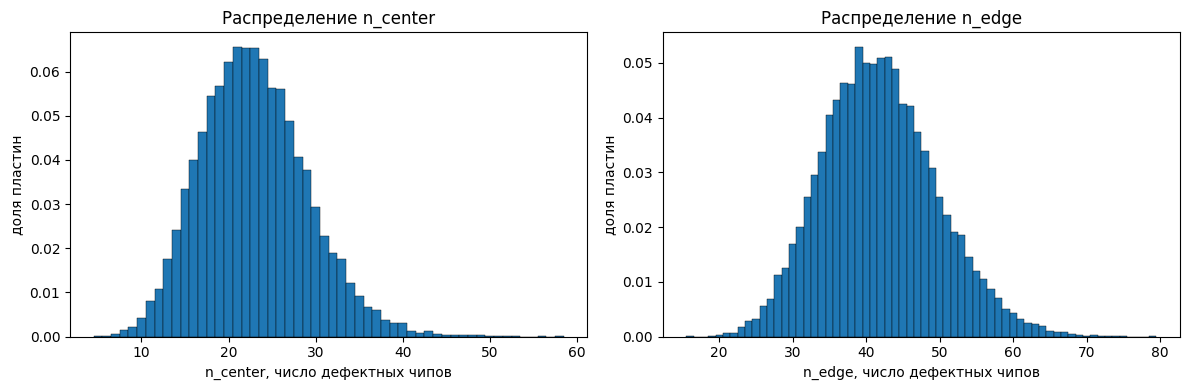

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, v) in zip(axes, [("n_center", c), ("n_edge", e)]):
    ax.hist(v, bins=np.arange(v.min(), v.max() + 2) - 0.5, density=True, edgecolor="k", linewidth=0.3)
    ax.set_xlabel(f"{name}, число дефектных чипов")
    ax.set_ylabel("доля пластин")
    ax.set_title(f"Распределение {name}")
plt.tight_layout()
plt.show()

#### Диаграмма рассеяния и тепловая карта

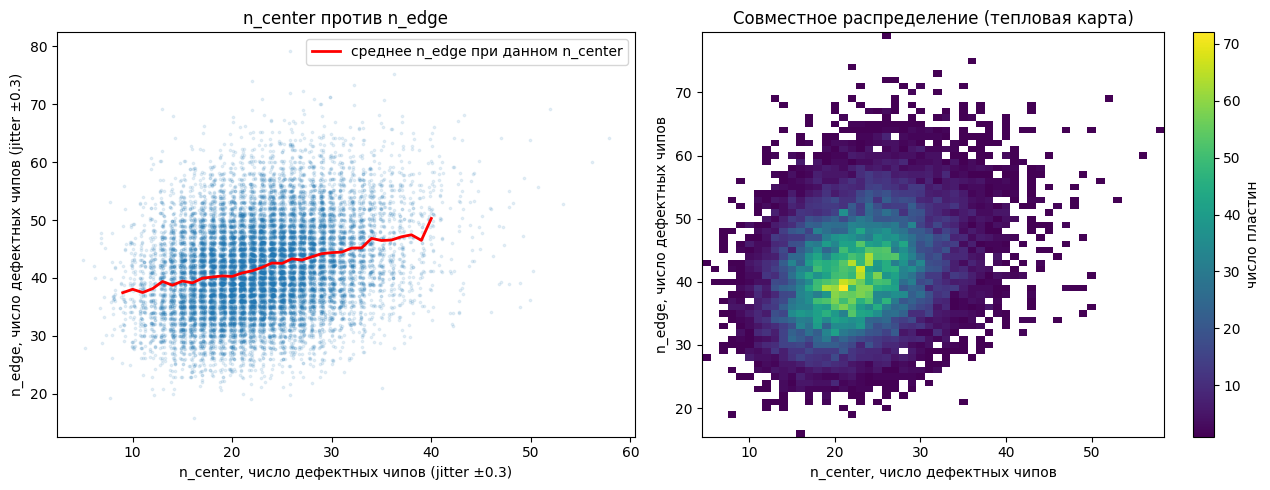

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(c + rng.uniform(-0.3, 0.3, N), e + rng.uniform(-0.3, 0.3, N), s=3, alpha=0.1)
cm = pd.Series(e).groupby(c).agg(["mean", "size"])
cm = cm[cm["size"] >= 30]
axes[0].plot(cm.index, cm["mean"], "r-", lw=2, label="среднее n_edge при данном n_center")
axes[0].set_xlabel("n_center, число дефектных чипов (jitter ±0.3)")
axes[0].set_ylabel("n_edge, число дефектных чипов (jitter ±0.3)")
axes[0].set_title("n_center против n_edge")
axes[0].legend()

h = axes[1].hist2d(c, e, bins=[np.arange(c.min(), c.max() + 2) - 0.5,
                               np.arange(e.min(), e.max() + 2) - 0.5], cmap="viridis", cmin=1)
fig.colorbar(h[3], ax=axes[1], label="число пластин")
axes[1].set_xlabel("n_center, число дефектных чипов")
axes[1].set_ylabel("n_edge, число дефектных чипов")
axes[1].set_title("Совместное распределение (тепловая карта)")
plt.tight_layout()
plt.show()

### Correlation & Tests

#### Коэффициенты корреляции

- **Пирсон** $r=\frac{\sum(x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum(x_i-\bar x)^2\sum(y_i-\bar y)^2}}$ измеряет только **линейную** связь и чувствителен к выбросам.
- **Спирмен** $\rho$ — тот же Пирсон, но на рангах. Он измеряет **монотонную** связь, а для одинаковых значений (у нас целые числа, ничьих много) ставятся средние ранги.
- **Кендалл** $\tau$ — доля согласованных пар минус доля несогласованных.

Важно: $r=0$ не означает независимости (например, $Y=X^2$ при симметричном $X$ даёт $r=0$). Обратное верно: если корреляция значимо не равна нулю, величины зависимы.

Результат: $r=0.279$ (95% ДИ $[0.265;\ 0.294]$), $\rho=0.266$, $\tau=0.187$, все p-value $<10^{-250}$. Связь **положительная, слабая–умеренная**: $r^2\approx0.08$, то есть n_center «объясняет» около 8% дисперсии n_edge. По диаграмме рассеяния видно облако с наклоном, и среднее n_edge (красная линия) растёт с ростом n_center почти линейно.

In [6]:
pr = stats.pearsonr(c, e)
sr = stats.spearmanr(c, e)
kt = stats.kendalltau(c, e)
corr_tab = pd.DataFrame({"коэффициент": [pr.statistic, sr.statistic, kt.statistic],
                         "p-value": [pr.pvalue, sr.pvalue, kt.pvalue]},
                        index=["Пирсон r", "Спирмен rho", "Кендалл tau"])
ci = pr.confidence_interval(0.95)
print(f"95% ДИ для r Пирсона: [{ci.low:.4f}, {ci.high:.4f}]")
corr_tab

95% ДИ для r Пирсона: [0.2650, 0.2937]


,коэффициент,p-value
Пирсон r,0.279383,1.352730e-282
Спирмен rho,0.265500,2.130895e-254
Кендалл tau,0.186708,1.041635e-251


#### Перестановочный тест

Перестановочный тест не опирается на предположения о распределении. Если $H_0$ верна, то какой n_edge стоит рядом с каким n_center — дело случая. Поэтому перемешиваем n_edge относительно n_center 2000 раз, каждый раз считаем $\rho$ и смотрим, насколько часто получается значение не меньше наблюдаемого по модулю:
$$p=\frac{1+\#\{|\rho^*|\ge|\rho_{obs}|\}}{N_{perm}+1}.$$

Результат: при перестановках $\rho^*$ в среднем 0, sd ≈ 0.008, максимум по модулю 0.025. Наблюдаемое 0.266 лежит очень далеко. Ни одна перестановка не дала такого значения, поэтому $p=1/2001\approx0.0005$ (это минимально возможное значение при 2000 перестановках). **$H_0$ отвергается.**

наблюдаемый rho = 0.2655
перестановки: среднее = 0.00006, sd = 0.00790, max |rho*| = 0.0253
p-value = 0.00050 (минимально возможное при 2000 перестановках: 0.00050)


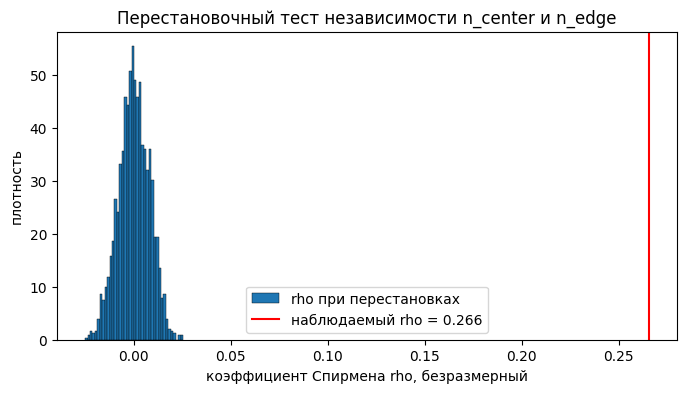

In [7]:
# Спирмен = Пирсон на рангах: ранжируем один раз, дальше переставляем ранги n_edge
rc = stats.rankdata(c)
re_ = stats.rankdata(e)
obs = np.corrcoef(rc, re_)[0, 1]
perm = np.array([np.corrcoef(rc, rng.permutation(re_))[0, 1] for _ in range(N_PERM)])
p_perm = (np.sum(np.abs(perm) >= abs(obs)) + 1) / (len(perm) + 1)
print(f"наблюдаемый rho = {obs:.4f}")
print(f"перестановки: среднее = {perm.mean():.5f}, sd = {perm.std():.5f}, max |rho*| = {np.abs(perm).max():.4f}")
print(f"p-value = {p_perm:.5f} (минимально возможное при {N_PERM} перестановках: {1 / (N_PERM + 1):.5f})")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(perm, bins=40, density=True, edgecolor="k", linewidth=0.3, label="rho при перестановках")
ax.axvline(obs, color="r", label=f"наблюдаемый rho = {obs:.3f}")
ax.set_xlabel("коэффициент Спирмена rho, безразмерный")
ax.set_ylabel("плотность")
ax.set_title("Перестановочный тест независимости n_center и n_edge")
ax.legend()
plt.show()

#### Таблица сопряжённости и хи-квадрат независимости

χ²-критерий независимости сравнивает наблюдаемые частоты в таблице сопряжённости $O_{ij}$ с ожидаемыми при независимости $E_{ij}=R_iC_j/n$:
$$\chi^2=\sum_{i,j}\frac{(O_{ij}-E_{ij})^2}{E_{ij}}\sim\chi^2_{(r-1)(c-1)}.$$
Условие применимости: все $E_{ij}\ge5$.

Группы 0 / 1 / 2 / 3+, предложенные в задании, здесь не работают: минимум n_center = 5, минимум n_edge = 16, и все пластины попадают в одну клетку «3+» (таблица ниже). Поэтому делим каждую величину на 5 групп по квинтилям. Так в каждой группе примерно по 20% пластин, и ожидаемые частоты большие (минимум 528).

Силу связи оцениваем по $V$ Крамера: $V=\sqrt{\frac{\chi^2}{n\,\min(r-1,c-1)}}$, $V\in[0,1]$. При $n\approx16000$ p-value будет крошечным даже при очень слабой связи, поэтому смотреть надо именно на $V$.

In [8]:
# группы 0 / 1 / 2 / 3+ из задания: все пластины попадают в 3+
cut4 = lambda s: pd.cut(s, [-0.5, 0.5, 1.5, 2.5, np.inf], labels=["0", "1", "2", "3+"])
pd.crosstab(cut4(df["n_center"]), cut4(df["n_edge"]), margins=True)

n_edge,3+,All
n_center,,
3+,15881,15881
All,15881,15881


In [9]:
# группы по квинтилям каждой величины
Q = 5
gc = pd.qcut(df["n_center"], Q)
ge = pd.qcut(df["n_edge"], Q)
tab = pd.crosstab(gc, ge)
chi2, p_chi2, dof, E = stats.chi2_contingency(tab)
V = stats.contingency.association(tab, method="cramer")
print(f"chi2 = {chi2:.2f}, df = {dof}, p = {p_chi2:.3e}")
print(f"min ожидаемая частота = {E.min():.1f} (условие E >= 5: {(E >= 5).all()})")
print(f"V Крамера = {V:.4f}")
tab

chi2 = 1091.20, df = 16, p = 3.235e-222
min ожидаемая частота = 528.4 (условие E >= 5: True)
V Крамера = 0.1311


n_edge,"(15.999, 35.0]","(35.0, 39.0]","(39.0, 43.0]","(43.0, 48.0]","(48.0, 79.0]"
n_center,,,,,
"(4.999, 18.0]",1243,783,769,642,431
"(18.0, 21.0]",730,659,605,522,416
"(21.0, 24.0]",610,613,654,645,555
"(24.0, 28.0]",498,548,651,801,705
"(28.0, 58.0]",287,393,528,647,946


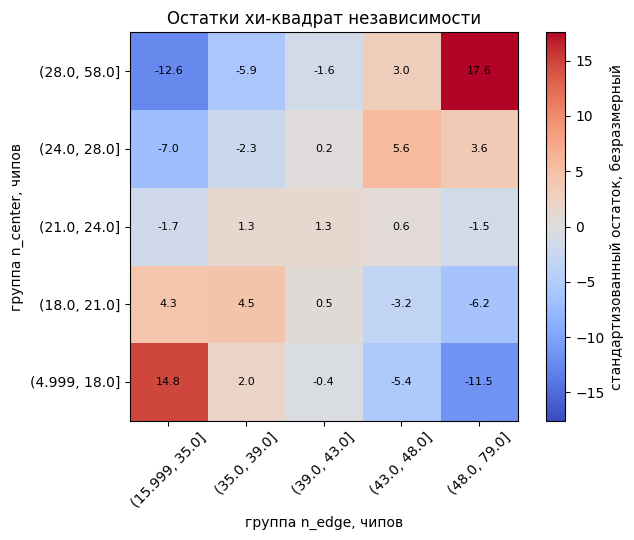

In [10]:
# стандартизованные остатки (O - E) / sqrt(E): где совместных случаев больше / меньше, чем при независимости
resid = (tab - E) / np.sqrt(E)
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(resid.values, cmap="coolwarm", vmin=-np.abs(resid.values).max(), vmax=np.abs(resid.values).max(),
               origin="lower")
ax.set_xticks(range(Q), [str(i) for i in ge.cat.categories], rotation=45)
ax.set_yticks(range(Q), [str(i) for i in gc.cat.categories])
for i in range(Q):
    for j in range(Q):
        ax.text(j, i, f"{resid.values[i, j]:.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="стандартизованный остаток, безразмерный")
ax.set_xlabel("группа n_edge, чипов")
ax.set_ylabel("группа n_center, чипов")
ax.set_title("Остатки хи-квадрат независимости")
plt.tight_layout()
plt.show()

### Условная независимость

Мы получили положительную связь. Теперь проверим, откуда она берётся: от общего уровня брака на пластине (модель 2) или от чего-то ещё. Для этого фиксируем общее число дефектов n_defect.

**Мультиномиальная модель.** Пусть при данном $N$ каждый дефект независимо попадает в центр ($p_c$), в промежуточное кольцо ($p_m$) или на край ($p_e$). Тогда
$$\operatorname{Cov}(n_c,n_e\mid N)=-Np_cp_e,\qquad \operatorname{corr}(n_c,n_e\mid N)=-\sqrt{\frac{p_cp_e}{(1-p_c)(1-p_e)}},$$
а без условия (по закону полной ковариации)
$$\operatorname{Cov}(n_c,n_e)=\mathbb E[-Np_cp_e]+\operatorname{Cov}(Np_c,Np_e)=p_cp_e(\operatorname{Var}N-\mathbb EN).$$
Положительна она, только если $\operatorname{Var}N>\mathbb EN$, то есть при перерассеянии $N$. У нас $D(N)=3.08$.

**Частная корреляция** Спирмена при контроле n_defect:
$$\rho_{ce\cdot d}=\frac{\rho_{ce}-\rho_{cd}\rho_{ed}}{\sqrt{(1-\rho_{cd}^2)(1-\rho_{ed}^2)}}.$$
Ещё проверяем корреляции **внутри страт** n_defect (по децилям) и перестановочный тест, в котором n_edge перемешивается только внутри своей страты.

In [11]:
# доли зон в общем числе дефектов и проверка модели "общий уровень дефектности"
p_c = c.sum() / d.sum()
p_e = e.sum() / d.sum()
cov_obs = np.cov(c, e)[0, 1]
# мультиномиальная схема при случайном N: Cov = p_c p_e (Var N - E N)
cov_mult = p_c * p_e * (d.var(ddof=1) - d.mean())
# одна общая случайная интенсивность (гамма-смесь Пуассона): Cov^2 = (Var c - E c)(Var e - E e)
cov_gamma = np.sqrt((c.var(ddof=1) - c.mean()) * (e.var(ddof=1) - e.mean()))
# при фиксированном N: corr = -sqrt(p_c p_e / ((1 - p_c)(1 - p_e)))
corr_fixed = -np.sqrt(p_c * p_e / ((1 - p_c) * (1 - p_e)))
pd.Series({"p_c (доля дефектов в центре)": p_c,
           "p_e (доля дефектов у края)": p_e,
           "Cov наблюдаемая": cov_obs,
           "Cov мультиномиальная, N случайно": cov_mult,
           "Cov одна гамма-интенсивность": cov_gamma,
           "corr теория при фиксированном N": corr_fixed}).round(4)

p_c (доля дефектов в центре)         0.2335
p_e (доля дефектов у края)           0.4258
Cov наблюдаемая                     13.3345
Cov мультиномиальная, N случайно    20.3409
Cov одна гамма-интенсивность        16.5765
corr теория при фиксированном N     -0.4753
dtype: float64

In [12]:
# частная корреляция Спирмена при контроле n_defect
rho = lambda a, b: stats.spearmanr(a, b).statistic
r_ce, r_cd, r_ed = rho(c, e), rho(c, d), rho(e, d)
partial = (r_ce - r_cd * r_ed) / np.sqrt((1 - r_cd**2) * (1 - r_ed**2))
pd.Series({"rho(c, e)": r_ce, "rho(c, n_defect)": r_cd, "rho(e, n_defect)": r_ed,
           "частная rho(c, e | n_defect)": partial}).round(4)

rho(c, e)                       0.2655
rho(c, n_defect)                0.6831
rho(e, n_defect)                0.7340
частная rho(c, e | n_defect)   -0.4756
dtype: float64

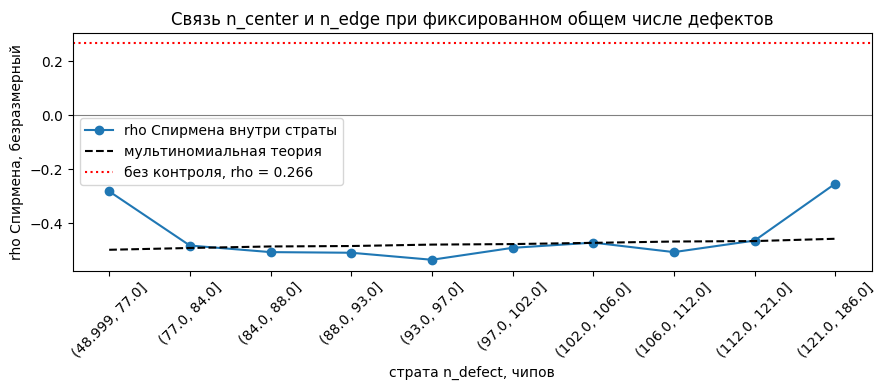

,страта n_defect,n,rho,p-value,теория при фикс. N
0,"(48.999, 77.0]",1698,-0.2813,0.0,-0.4973
1,"(77.0, 84.0]",1745,-0.4816,0.0,-0.4906
2,"(84.0, 88.0]",1383,-0.5059,0.0,-0.4850
3,"(88.0, 93.0]",1732,-0.5083,0.0,-0.4834
4,"(93.0, 97.0]",1507,-0.5342,0.0,-0.4781
5,"(97.0, 102.0]",1786,-0.4901,0.0,-0.4762
6,"(102.0, 106.0]",1278,-0.4709,0.0,-0.4717
7,"(106.0, 112.0]",1601,-0.5059,0.0,-0.4668
8,"(112.0, 121.0]",1618,-0.4633,0.0,-0.4651
9,"(121.0, 186.0]",1533,-0.2529,0.0,-0.4566


In [13]:
# корреляции внутри страт n_defect (децили)
strata = pd.qcut(df["n_defect"], 10)
rows = []
for lab, idx in df.groupby(strata, observed=True).groups.items():
    s = df.loc[idx]
    sr_ = stats.spearmanr(s["n_center"], s["n_edge"])
    pc_ = s["n_center"].sum() / s["n_defect"].sum()
    pe_ = s["n_edge"].sum() / s["n_defect"].sum()
    rows.append({"страта n_defect": str(lab), "n": len(s), "rho": sr_.statistic, "p-value": sr_.pvalue,
                 "теория при фикс. N": -np.sqrt(pc_ * pe_ / ((1 - pc_) * (1 - pe_)))})
strat_tab = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 4))
xs = np.arange(len(strat_tab))
ax.plot(xs, strat_tab["rho"], "o-", label="rho Спирмена внутри страты")
ax.plot(xs, strat_tab["теория при фикс. N"], "k--", label="мультиномиальная теория")
ax.axhline(0, color="gray", lw=0.8)
ax.axhline(r_ce, color="r", ls=":", label=f"без контроля, rho = {r_ce:.3f}")
ax.set_xticks(xs, strat_tab["страта n_defect"], rotation=45)
ax.set_xlabel("страта n_defect, чипов")
ax.set_ylabel("rho Спирмена, безразмерный")
ax.set_title("Связь n_center и n_edge при фиксированном общем числе дефектов")
ax.legend()
plt.tight_layout()
plt.show()
strat_tab.round(4)

In [14]:
# перестановочный тест внутри страт: n_edge перемешивается только среди пластин с похожим n_defect
codes = strata.cat.codes.to_numpy()
groups = [np.flatnonzero(codes == g) for g in np.unique(codes)]

def within_stat(e_arr):
    return np.mean([stats.spearmanr(c[ix], e_arr[ix]).statistic for ix in groups])

obs_w = within_stat(e)
perm_w = np.empty(200)
for b in range(len(perm_w)):
    e_b = e.copy()
    for ix in groups:
        e_b[ix] = rng.permutation(e[ix])
    perm_w[b] = within_stat(e_b)
p_w = (np.sum(np.abs(perm_w) >= abs(obs_w)) + 1) / (len(perm_w) + 1)
print(f"средний rho внутри страт = {obs_w:.4f}; при перестановках: {perm_w.mean():.4f} ± {perm_w.std():.4f}; p = {p_w:.4f}")

средний rho внутри страт = -0.4494; при перестановках: -0.0002 ± 0.0075; p = 0.0050


#### Лоты: общий фактор партии

Ещё одна общая причина — лот (партия). Пластины одного лота проходят обработку вместе, поэтому средние по лоту могут быть связаны. Сравниваем корреляцию между **средними по лотам** и корреляцию **отклонений от среднего своего лота**.

Результат: между средними по лотам $\rho=0.65$, внутри лотов $\rho=0.19$. Большая часть положительной связи идёт от партии: в «грязных» лотах больше брака и в центре, и на краю. Но и внутри одного лота связь остаётся, так как уровень брака меняется и от пластины к пластине.

In [15]:
big = df["lotName"].map(df["lotName"].value_counts()) >= 10     # лоты хотя бы из 10 пластин
c_dev = (df["n_center"] - df.groupby("lotName")["n_center"].transform("mean"))[big]
e_dev = (df["n_edge"] - df.groupby("lotName")["n_edge"].transform("mean"))[big]
lot_means = df[big].groupby("lotName")[["n_center", "n_edge"]].mean()
pd.Series({
    "лотов (>= 10 пластин)": lot_means.shape[0],
    "rho между средними по лотам": stats.spearmanr(lot_means["n_center"], lot_means["n_edge"]).statistic,
    "rho внутри лотов (отклонения от среднего лота)": stats.spearmanr(c_dev, e_dev).statistic,
}).round(4)

лотов (>= 10 пластин)                             715.0000
rho между средними по лотам                         0.6483
rho внутри лотов (отклонения от среднего лота)      0.1913
dtype: float64

#### Монте-Карло: модель «общий уровень дефектности + случайное место»

Проверяем, может ли простая модель воспроизвести всё сразу. Число дефектов $N$ берём из данных (бутстрап n_defect), а каждый дефект независимо отправляем в центр, кольцо или на край с долями $p_c, p_m, p_e$ из данных. Других связей в модели нет.

Модель воспроизводит главное: положительную маргинальную корреляцию (0.36) и отрицательную при фиксированном $N$ (≈ −0.40…−0.44). То есть **вся** картина объясняется общим уровнем брака плюс «конкуренцией» зон за фиксированное число дефектов.

В деталях данные немного отличаются: маргинальная связь слабее (0.27 против 0.36), условная сильнее отрицательная (−0.45 против −0.40). Наблюдаемая ковариация 13.3 тоже меньше мультиномиального прогноза 20.3. Это значит, что доли $p_c$ и $p_e$ сами немного меняются от пластины к пластине: на одних пластинах брак больше в центре, на других больше у края. Такая изменчивость долей добавляет отрицательную ковариацию. С этим согласуется и результат из ноутбука r_def: центроид дефектов «гуляет» сильнее, чем при независимой раскладке.

In [16]:
# N берётся из данных (бутстрап n_defect), место каждого дефекта независимо: центр / кольцо / край
p_m = 1 - p_c - p_e
d_sim = rng.choice(d, N, replace=True)
sim = np.array([rng.multinomial(k, [p_c, p_m, p_e]) for k in d_sim])
c_sim, e_sim = sim[:, 0], sim[:, 2]
strata_sim = pd.qcut(pd.Series(d_sim), 10, duplicates="drop").cat.codes.to_numpy()
within_sim = np.mean([stats.spearmanr(c_sim[strata_sim == g], e_sim[strata_sim == g]).statistic
                      for g in np.unique(strata_sim)])
pd.DataFrame({
    "данные": [r_ce, partial, strat_tab["rho"].mean()],
    "модель": [rho(c_sim, e_sim),
               (rho(c_sim, e_sim) - rho(c_sim, d_sim) * rho(e_sim, d_sim))
               / np.sqrt((1 - rho(c_sim, d_sim)**2) * (1 - rho(e_sim, d_sim)**2)),
               within_sim],
}, index=["rho(c, e)", "частная rho | n_defect", "средний rho внутри страт"]).round(4)

,данные,модель
"rho(c, e)",0.2655,0.3628
частная rho | n_defect,-0.4756,-0.4442
средний rho внутри страт,-0.4494,-0.4049


#### Сводная таблица

In [17]:
pd.Series({
    "пластин": N,
    "Пирсон r": pr.statistic, "Пирсон p": pr.pvalue,
    "Спирмен rho": sr.statistic, "Спирмен p": sr.pvalue,
    "перестановочный p": p_perm,
    "chi2 независимости": chi2, "df": dof, "chi2 p": p_chi2, "V Крамера": V,
    "частная rho | n_defect": partial,
    "средний rho внутри страт n_defect": obs_w,
    "p (перестановки внутри страт)": p_w,
    "Cov наблюдаемая": cov_obs,
    "Cov мультиномиальная модель": cov_mult,
}, dtype=object).map(lambda v: f"{v:.6g}" if isinstance(v, (float, np.floating)) else v).to_frame("значение")

,значение
пластин,15881
Пирсон r,0.279383
Пирсон p,1.35273e-282
Спирмен rho,0.2655
Спирмен p,2.1309e-254
перестановочный p,0.00049975
chi2 независимости,1091.2
df,16
chi2 p,3.23488e-222
V Крамера,0.131064


### Выводы

1. **Независимость n_center и n_edge отвергнута** всеми четырьмя способами: Пирсон $r=0.28$, Спирмен $\rho=0.27$ (p-value $<10^{-250}$), перестановочный тест $p=0.0005$ (минимально возможное), χ² независимости по квинтилям $\chi^2=1091$, $df=16$, $p\sim10^{-222}$.
2. Связь **положительная, но слабая**: $V$ Крамера = 0.13, $r^2\approx0.08$. Статистически она значима из-за огромного $n$, а практически по n_center плохо предсказывается n_edge. По остаткам χ² видно, что «мало–мало» и «много–много» встречаются чаще, чем при независимости, а «мало–много» реже.
3. Причина — **общий уровень дефектности** пластины и лота. Это не «физическое взаимодействие» центра и края: когда пластина в целом грязнее (загрязнение камеры, партия реагентов, состояние оборудования в этом лоте), брака больше везде. Связь между средними по лотам ($\rho=0.65$) намного сильнее, чем внутри лотов ($0.19$).
4. Если зафиксировать общее число дефектов, **знак связи меняется**: частная корреляция $\rho_{ce\cdot d}=-0.48$. Это почти точно совпадает с мультиномиальной теорией ($-0.475$). При фиксированном $N$ зоны просто делят дефекты между собой, это арифметика, а не физика.
5. Простая модель «случайный общий уровень брака + независимое место каждого дефекта» объясняет и знак, и порядок величины обеих корреляций. Небольшие расхождения указывают на то, что доля брака в центре и на краю ещё немного меняется от пластины к пластине.
6. Независимость в классе none была бы правдоподобна, только если бы число дефектов было пуассоновским с одинаковой интенсивностью для всех пластин. Но у n_center, n_edge и n_defect есть перерассеяние ($D=1.6,\ 1.5,\ 3.1$), так что этого нет.
7. Общие выводы: корреляция ≠ причинность (центр не «вызывает» брак на краю, у них общая причина), и нулевая корреляция ≠ независимость (здесь не понадобилось, потому что корреляция не нулевая).

Оговорка: пластины одного лота не независимы, поэтому p-value классических тестов занижены. Но при таких значениях (и при перестановочном тесте) это не меняет вывод.

#### Литература

1. Гмурман В. Е. Теория вероятностей и математическая статистика. — М.: Юрайт, 2016 (корреляция, χ² независимости).
2. Кобзарь А. И. Прикладная математическая статистика. — М.: Физматлит, 2006 (ранговые корреляции, частная корреляция).
3. Ивченко Г. И., Медведев Ю. И. Введение в математическую статистику. — М.: ЛКИ, 2010.
4. Efron B., Tibshirani R. J. An Introduction to the Bootstrap. — Chapman & Hall, 1993 (перестановочные тесты).
5. Stapper C. H. Defect Density Distribution for LSI Yield Calculations // IEEE Trans. Electron Devices. 1973. Vol. ED-20. P. 655–657.
6. Stapper C. H., Armstrong F. M., Saji K. Integrated Circuit Yield Statistics // Proc. IEEE. 1983. Vol. 71, № 4. P. 453–470.
7. Bogdanov Yu. I., Bogdanova N. A., Dshkhunyan V. L. Statistical Yield Modeling for IC Manufacture: Hierarchical Fault Distributions // Russian Microelectronics. 2003. Vol. 32, № 1. P. 51 (arXiv: physics/0303039).
8. Wu M.-J., Jang J.-S. R., Chen J.-L. Wafer Map Failure Pattern Recognition and Similarity Ranking for Large-Scale Data Sets // IEEE Trans. Semicond. Manuf. 2015. Vol. 28, № 1. P. 1–12.
9. Документация SciPy: `pearsonr`, `spearmanr`, `kendalltau`, `chi2_contingency`, `contingency.association`.